<img src="https://cdn.britannica.com/41/195741-050-E68CF3CA/California-united-states-locator-map.jpg" alt="California map" width="400"/>

# California Cities: a quick data analysis

In this notebook we use **Pandas** to inspect a table of California cities, **NumPy** to transform numerical data, and **Matplotlib** to find patterns with several charts.

### Topics
- Load and inspect a CSV dataset
- Select useful columns and check missing values
- Compare city populations and areas
- Build scatter plots, a ranked bar chart, and a histogram

**Question for the lesson:** Which cities are large, crowded, or geographically unusual?


> **Estimated time: 30 min**

## 1 · Import the tools

These three libraries cover the main workflow: tables, numerical operations, and visualizations.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


%matplotlib inline

## 2 · Load and inspect the table

The CSV file should be in the same folder as this notebook. Start with a small preview before analyzing the data.

In [2]:
cities = pd.read_csv('california_cities.csv')
print('Rows and columns:', cities.shape)

Rows and columns: (482, 14)


In [3]:
cities.head()

,Unnamed: 0,city,latd,longd,elevation_m,elevation_ft,population_total,area_total_sq_mi,area_land_sq_mi,area_water_sq_mi,area_total_km2,area_land_km2,area_water_km2,area_water_percent
0,0,Adelanto,34.576111,-117.432778,875.0,2871.0,31765,56.027,56.009,0.018,145.107,145.062,0.046,0.03
1,1,AgouraHills,34.153333,-118.761667,281.0,922.0,20330,7.822,7.793,0.029,20.260,20.184,0.076,0.37
2,2,Alameda,37.756111,-122.274444,NaN,33.0,75467,22.960,10.611,12.349,59.465,27.482,31.983,53.79
3,3,Albany,37.886944,-122.297778,NaN,43.0,18969,5.465,1.788,3.677,14.155,4.632,9.524,67.28
4,4,Alhambra,34.081944,-118.135000,150.0,492.0,83089,7.632,7.631,0.001,19.766,19.763,0.003,0.01


## 3 · Choose columns and check data quality

We keep the columns needed for today’s questions, And drop some columns that are not useful for this analysis.

In [4]:
print('Missing values:')
cities.isna().sum()

Missing values:


Unnamed: 0             0
city                   0
latd                   0
longd                  0
elevation_m           48
elevation_ft          12
population_total       0
area_total_sq_mi       2
area_land_sq_mi        0
area_water_sq_mi       1
area_total_km2         5
area_land_km2          4
area_water_km2         4
area_water_percent     5
dtype: int64

Convert elevation from feet to meters, and area from square miles to square kilometers if values are missing. 

We will keep the original values.

In [5]:
# cities["elevation_m"] = cities["elevation_ft"] * 0.3048
# cities["area_total_km2"] = cities["area_total_sq_mi"] * 2.58999
# cities["area_land_km2"] = cities["area_land_sq_mi"] * 2.58999
# cities["area_water_km2"] = cities["area_water_sq_mi"] * 2.58999

cities["elevation_m"] = cities["elevation_m"].fillna(cities["elevation_ft"] * 0.3048)
cities["area_total_km2"] = cities["area_total_km2"].fillna(cities["area_total_sq_mi"] * 2.58999)
cities["area_land_km2"] = cities["area_land_km2"].fillna(cities["area_land_sq_mi"] * 2.58999)
cities["area_water_km2"] = cities["area_water_km2"].fillna(cities["area_water_sq_mi"] * 2.58999)

In [6]:
print('Missing values:')
cities.isna().sum()

Missing values:


Unnamed: 0             0
city                   0
latd                   0
longd                  0
elevation_m            8
elevation_ft          12
population_total       0
area_total_sq_mi       2
area_land_sq_mi        0
area_water_sq_mi       1
area_total_km2         1
area_land_km2          0
area_water_km2         0
area_water_percent     5
dtype: int64

In [7]:
cities.drop(columns=['elevation_ft', 'area_total_sq_mi', 'area_land_sq_mi', 'area_water_sq_mi'], inplace=True)
cities.head()

/var/folders/xg/w42wrmyd6t71zwh8j373f_400000gn/T/ipykernel_37685/92150201.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  cities.drop(columns=['elevation_ft', 'area_total_sq_mi', 'area_land_sq_mi', 'area_water_sq_mi'], inplace=True)


,Unnamed: 0,city,latd,longd,elevation_m,population_total,area_total_km2,area_land_km2,area_water_km2,area_water_percent
0,0,Adelanto,34.576111,-117.432778,875.0000,31765,145.107,145.062,0.046,0.03
1,1,AgouraHills,34.153333,-118.761667,281.0000,20330,20.260,20.184,0.076,0.37
2,2,Alameda,37.756111,-122.274444,10.0584,75467,59.465,27.482,31.983,53.79
3,3,Albany,37.886944,-122.297778,13.1064,18969,14.155,4.632,9.524,67.28
4,4,Alhambra,34.081944,-118.135000,150.0000,83089,19.766,19.763,0.003,0.01


In [8]:
cities.describe().round(2)

,Unnamed: 0,latd,longd,elevation_m,population_total,area_total_km2,area_land_km2,area_water_km2,area_water_percent
count,482.00,482.00,482.00,474.00,482.00,481.00,482.00,482.00,477.00
mean,240.50,36.10,-119.84,173.07,64894.93,47.80,43.62,4.09,5.30
std,139.29,2.30,2.15,303.56,203204.10,94.06,84.67,24.55,14.66
min,0.00,32.58,-124.26,-54.86,1.00,0.81,0.81,0.00,0.00
25%,120.25,33.98,-121.95,21.00,10902.00,9.62,9.08,0.00,0.00
50%,240.50,36.20,-119.71,62.50,29057.50,23.55,21.66,0.08,0.34
75%,360.75,37.89,-117.98,158.50,66466.50,51.77,49.44,0.62,1.87
max,481.00,41.96,-114.60,2402.00,3884307.00,1302.00,1214.00,479.20,84.58


## 4 · Plot 1: a population map

Each dot is a city. 

Longitude and latitude position the city; dot size represents area, and color represents population. 

The logarithmic color scale helps us see both small and large cities.

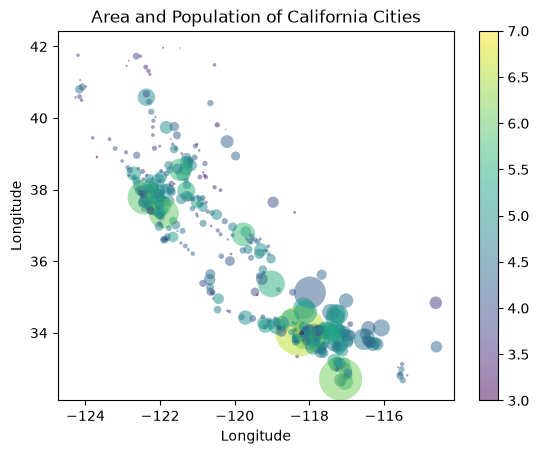

In [9]:
plt.scatter(
    cities['longd'],
    cities['latd'],
    cmap='viridis',
    c=np.log10(cities['population_total']),
    s=cities['area_total_km2'],
    linewidth=0, alpha=0.5
)

plt.xlabel('Longitude')
plt.ylabel('Longitude')
plt.colorbar()
plt.clim(3, 7)

plt.title("Area and Population of California Cities")
plt.show()

## 5 · Plot 2: the ten most populous cities

A horizontal bar chart is useful for ranking categories. Sorting the values makes the comparison easy to read.

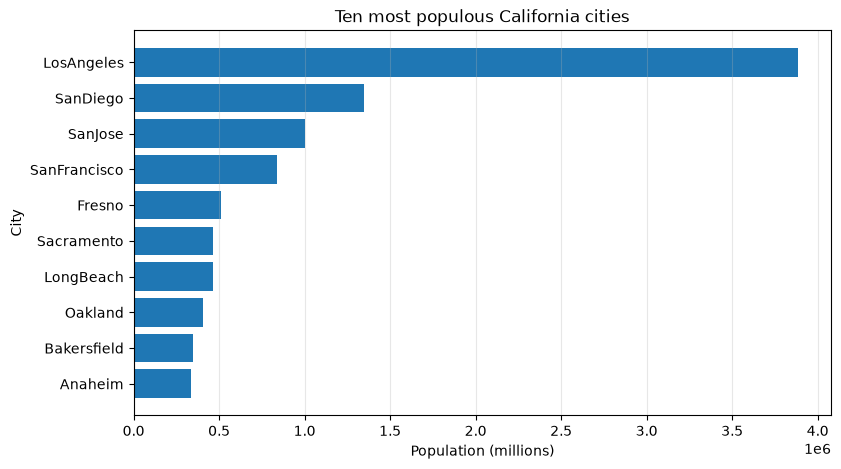

In [10]:
top_10 = cities.nlargest(10, 'population_total').sort_values('population_total')

plt.figure(figsize=(9, 5))
plt.barh(
    top_10['city'],
    top_10['population_total']
)
plt.xlabel('Population (millions)')
plt.ylabel('City')
plt.title('Ten most populous California cities')
plt.grid(axis='x', alpha=0.3)
plt.show()

## 6 · Plot 3: population and area

Does a larger city area mean a larger population? A scatter plot can reveal the relationship. We use logarithmic axes because the values vary widely.

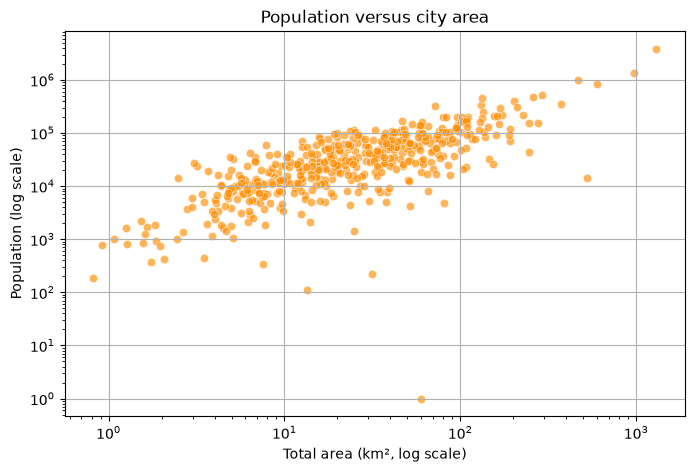

In [11]:
plt.figure(figsize=(8, 5))
plt.scatter(
    cities['area_total_km2'],
    cities['population_total'],
    color='darkorange',
    alpha=0.65,
    edgecolors='white',
    linewidth=0.5
)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Total area (km², log scale)')
plt.ylabel('Population (log scale)')
plt.title('Population versus city area')
plt.grid()
plt.show()

## 8 · Plot 4: distribution of population density

Density helps us compare how concentrated cities are. A histogram shows the shape of the distribution, while the median gives us a typical value.

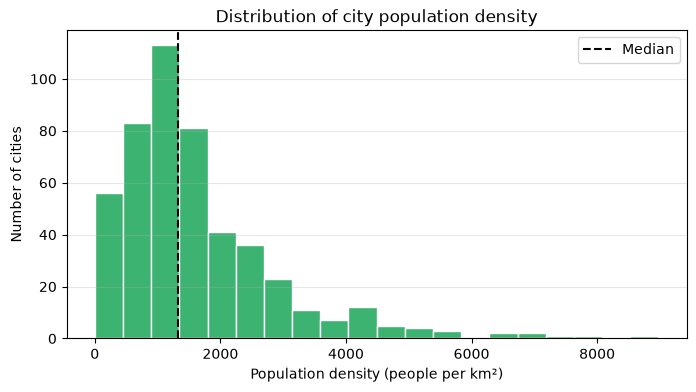

In [12]:
cities["population_density"] = cities["population_total"] / cities["area_land_km2"]

plt.figure(figsize=(8, 4))
plt.hist(cities['population_density'], bins=20, color='mediumseagreen', edgecolor='white')
plt.axvline(cities['population_density'].median(), color='black', linestyle='--', label='Median')
plt.xlabel('Population density (people per km²)')
plt.ylabel('Number of cities')
plt.title('Distribution of city population density')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

## Key takeaways

- Use `head()`, `shape`, `info()`, and `describe()` to understand a new dataset.
- Create meaningful columns, such as population density.
- Use a scatter plot for location or relationships and a bar chart for rankings.
- Good charts need clear titles, axis labels, units, and legends.

***

# Assignment
## Yasin Bagherian

***

Data Tyep: 
area_water_sq_mi    float64
area_water_km2      float64
dtype: object

Missing Values: 
area_water_sq_mi    1
area_water_km2      4
dtype: int64

Summary of Water-Area Columns: 
       area_water_sq_mi  area_water_km2
count        481.000000      478.000000
mean           1.589630        3.125178
std            9.490386       11.562269
min            0.000000        0.000000
25%            0.000000        0.000250
50%            0.029000        0.078500
75%            0.244000        0.623250
max          185.020000      122.270000

Top 5 cities by water area:
           city  area_water_km2
0  SanFrancisco        479.2018
1      SanDiego        122.2700
2    LosAngeles         88.0000
3  NewportBeach         75.5570
4      Coronado         64.0620


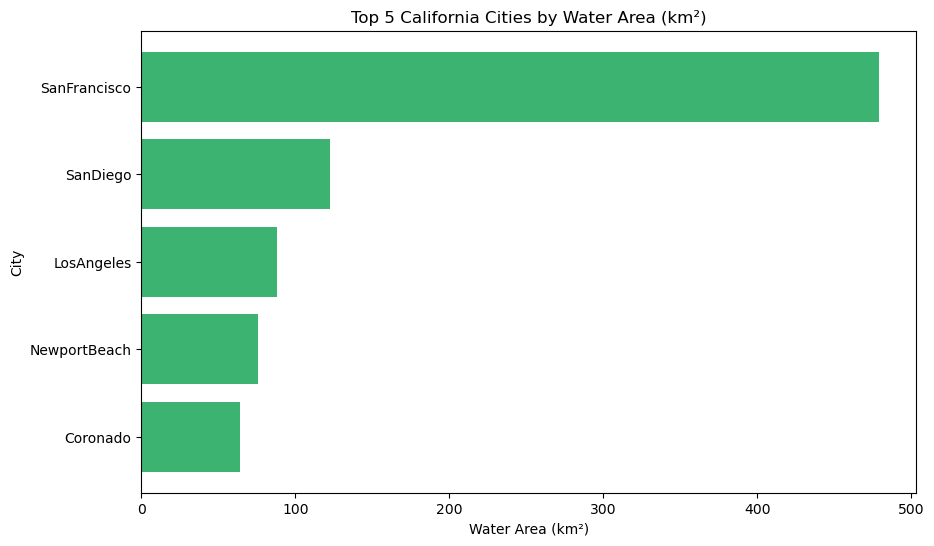

In [10]:
#imports have been done in the beggining of the file.
#خواندن فایل اکسل
cities_n= pd.read_csv('california_cities.csv')

#Check the data types and missing values in the water-area columns.
water_cols= ['area_water_sq_mi','area_water_km2']
print('Data Tyep: ')
print(cities_n[water_cols].dtypes)

print('\nMissing Values: ')
print(cities_n[water_cols].isnull().sum())

print('\nSummary of Water-Area Columns: ')
print(cities_n[water_cols].describe())

cities_n['area_water_km2'] = cities_n['area_water_km2'].fillna(
    cities_n['area_water_sq_mi'] * 2.59
)

#Rank the cities by `area_water_km2` and display the top five.
top_water_cities = cities_n.nlargest(5, 'area_water_km2').reset_index()
print('\nTop 5 cities by water area:')
print(top_water_cities[['city', 'area_water_km2']])

#Create a clearly labeled horizontal bar chart of the 5 cities and their water areas.
plt.figure(figsize=(10, 6))
plt.barh(top_water_cities['city'], top_water_cities['area_water_km2'], color='mediumseagreen')
plt.xlabel('Water Area (km²)')
plt.ylabel('City')
plt.title('Top 5 California Cities by Water Area (km²)')
plt.gca().invert_yaxis()  # Invert y-axis to have the largest city at the top
plt.show()
